In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

print("Libraries imported successfully!")

c:\Users\saish\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported successfully!


In [3]:
with open("company_documentation.txt", "r", encoding="utf-8") as file:
    company_docs = file.read()

print("Company documentation loaded successfully.")
print("Total characters:", len(company_docs))
print("\nDocument preview:\n")
print(company_docs[:500])

Company documentation loaded successfully.
Total characters: 2065

Document preview:

# NovaTech Company Documentation

## Company Overview
NovaTech Solutions is a technology company founded in 2018. It develops AI-powered software, cloud applications, and data analytics solutions for businesses. Its main office is located in Hyderabad, India.

## Working Hours
The standard working hours are Monday to Friday, from 9:30 AM to 6:00 PM. Employees should contact their team manager if they need an exception to the regular schedule.

## Leave Policy
Employees receive 18 paid leaves per


In [4]:
def create_chunks(text, chunk_size=500, overlap=100):
    chunks = []

    start = 0

    while start < len(text):
        end = start + chunk_size
        chunk = text[start:end].strip()

        if chunk:
            chunks.append(chunk)

        start += chunk_size - overlap

    return chunks


chunks = create_chunks(
    company_docs,
    chunk_size=500,
    overlap=100
)

print("Number of chunks:", len(chunks))

for i, chunk in enumerate(chunks[:3], start=1):
    print(f"\nChunk {i}:\n{chunk}")

Number of chunks: 6

Chunk 1:
# NovaTech Company Documentation

## Company Overview
NovaTech Solutions is a technology company founded in 2018. It develops AI-powered software, cloud applications, and data analytics solutions for businesses. Its main office is located in Hyderabad, India.

## Working Hours
The standard working hours are Monday to Friday, from 9:30 AM to 6:00 PM. Employees should contact their team manager if they need an exception to the regular schedule.

## Leave Policy
Employees receive 18 paid leaves per

Chunk 2:
hey need an exception to the regular schedule.

## Leave Policy
Employees receive 18 paid leaves per calendar year. Leave requests should be submitted through the company's HR portal and approved by the reporting manager before the leave begins, except in emergencies.

## Work From Home Policy
Employees may work from home up to two days per week, subject to manager approval and project requirements. Employees must remain reachable during working hours.

#

In [5]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

print("Embedding model loaded successfully!")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1722.39it/s]


Embedding model loaded successfully!


In [6]:
chunk_embeddings = embedding_model.encode(
    chunks,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Number of chunks:", len(chunks))
print("Embedding shape:", chunk_embeddings.shape)
print("First embedding preview:")
print(chunk_embeddings[0][:10])

Number of chunks: 6
Embedding shape: (6, 384)
First embedding preview:
[-0.04951397 -0.01217765  0.03541635 -0.04224535 -0.01698256 -0.06019695
  0.01613552 -0.03815554 -0.05457978  0.03664003]


In [7]:
def semantic_search(question, chunks, embeddings, top_k=3):
    question_embedding = embedding_model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    similarities = cosine_similarity(
        question_embedding,
        embeddings
    )[0]

    top_indices = np.argsort(similarities)[::-1][:top_k]

    results = []

    for idx in top_indices:
        results.append({
            "Chunk": chunks[idx],
            "Similarity Score": round(float(similarities[idx]), 4)
        })

    return pd.DataFrame(results)


question = "How many paid leaves do employees receive?"

results = semantic_search(
    question,
    chunks,
    chunk_embeddings,
    top_k=3
)

display(results)

,Chunk,Similarity Score
0,hey need an exception to the regular schedule....,0.5577
1,e portal within 30 days of the expense date. R...,0.2994
2,e shared with unauthorized individuals. Suspic...,0.2481


In [8]:
test_questions = [
    "How many paid leaves do employees receive?",
    "Can employees work remotely?",
    "How can I contact IT support?",
    "What security measures are required?",
    "When should new employees complete onboarding?"
]

for question in test_questions:
    print("\nQuestion:", question)

    results = semantic_search(
        question, chunks, chunk_embeddings, top_k=1
    )

    print("Retrieved document:")
    print(results.iloc[0]["Chunk"])
    print("Similarity:", results.iloc[0]["Similarity Score"])


Question: How many paid leaves do employees receive?
Retrieved document:
hey need an exception to the regular schedule.

## Leave Policy
Employees receive 18 paid leaves per calendar year. Leave requests should be submitted through the company's HR portal and approved by the reporting manager before the leave begins, except in emergencies.

## Work From Home Policy
Employees may work from home up to two days per week, subject to manager approval and project requirements. Employees must remain reachable during working hours.

## IT Support
Employees can contact the IT
Similarity: 0.5577

Question: Can employees work remotely?
Retrieved document:
s. Employees must remain reachable during working hours.

## IT Support
Employees can contact the IT support team by emailing itsupport@novatech.example. IT support handles laptop issues, software installation requests, network problems, and account-access issues.

## Security Policy
Employees must use strong passwords and enable multi-factor a

In [9]:
import chromadb

print("ChromaDB version:", chromadb.__version__)

ChromaDB version: 1.5.9


In [10]:
client = chromadb.Client()

collection = client.create_collection(
    name="novatech_company_docs",
    metadata={"hnsw:space": "cosine"}
)

collection.add(
    ids=[f"chunk_{i}" for i in range(len(chunks))],
    documents=chunks,
    embeddings=chunk_embeddings.tolist()
)

print("Documents stored in ChromaDB successfully!")
print("Total stored documents:", collection.count())

Documents stored in ChromaDB successfully!
Total stored documents: 6


In [11]:
collection = client.get_or_create_collection(
    name="novatech_company_docs",
    metadata={"hnsw:space": "cosine"}
)

In [12]:
question = "Can employees work from home?"

question_embedding = embedding_model.encode(
    [question],
    normalize_embeddings=True
)

retrieved = collection.query(
    query_embeddings=question_embedding.tolist(),
    n_results=min(3, len(chunks))
)

for i, document in enumerate(retrieved["documents"][0], start=1):
    print(f"\nRetrieved chunk {i}:")
    print(document)


Retrieved chunk 1:
hey need an exception to the regular schedule.

## Leave Policy
Employees receive 18 paid leaves per calendar year. Leave requests should be submitted through the company's HR portal and approved by the reporting manager before the leave begins, except in emergencies.

## Work From Home Policy
Employees may work from home up to two days per week, subject to manager approval and project requirements. Employees must remain reachable during working hours.

## IT Support
Employees can contact the IT

Retrieved chunk 2:
s. Employees must remain reachable during working hours.

## IT Support
Employees can contact the IT support team by emailing itsupport@novatech.example. IT support handles laptop issues, software installation requests, network problems, and account-access issues.

## Security Policy
Employees must use strong passwords and enable multi-factor authentication where available. Company data must not be shared with unauthorized individuals. Suspicious emails s

In [13]:
import faiss

dimension = chunk_embeddings.shape[1]

faiss_index = faiss.IndexFlatIP(dimension)
faiss_index.add(chunk_embeddings.astype("float32"))

question = "How many paid leaves do employees get?"

question_embedding = embedding_model.encode(
    [question],
    normalize_embeddings=True
).astype("float32")

scores, indices = faiss_index.search(
    question_embedding,
    min(3, len(chunks))
)

for rank, (idx, score) in enumerate(
    zip(indices[0], scores[0]), start=1
):
    print(f"\nRank {rank} | Similarity: {score:.4f}")
    print(chunks[idx])


Rank 1 | Similarity: 0.5555
hey need an exception to the regular schedule.

## Leave Policy
Employees receive 18 paid leaves per calendar year. Leave requests should be submitted through the company's HR portal and approved by the reporting manager before the leave begins, except in emergencies.

## Work From Home Policy
Employees may work from home up to two days per week, subject to manager approval and project requirements. Employees must remain reachable during working hours.

## IT Support
Employees can contact the IT

Rank 2 | Similarity: 0.2884
e portal within 30 days of the expense date. Reimbursement requests require manager approval.

## Performance Reviews
Employee performance reviews take place twice a year. Reviews consider work quality, teamwork, goal completion, and professional development.

## New Employee Onboarding
New employees must complete HR documentation, attend an orientation session, configure their company accounts, and complete mandatory security training d

In [14]:
import re

def generate_rag_answer(question, chunks, embeddings, top_k=3):
    retrieved_results = semantic_search(
        question,
        chunks,
        embeddings,
        top_k=top_k
    )

    context = "\n".join(retrieved_results["Chunk"].tolist())

    sentences = re.split(r'(?<=[.!?])\s+', context)

    question_embedding = embedding_model.encode(
        [question],
        normalize_embeddings=True
    )

    sentence_embeddings = embedding_model.encode(
        sentences,
        normalize_embeddings=True
    )

    similarities = cosine_similarity(
        question_embedding,
        sentence_embeddings
    )[0]

    best_index = int(np.argmax(similarities))
    answer = sentences[best_index]

    return {
        "Question": question,
        "Answer": answer,
        "Retrieved Context": context
    }

In [15]:
question = "How many paid leaves do employees receive?"

response = generate_rag_answer(
    question,
    chunks,
    chunk_embeddings
)

print("Question:", response["Question"])
print("\nGenerated Answer:", response["Answer"])
print("\nRetrieved Context:\n", response["Retrieved Context"])

Question: How many paid leaves do employees receive?

Generated Answer: ## Leave Policy
Employees receive 18 paid leaves per calendar year.

Retrieved Context:
 hey need an exception to the regular schedule.

## Leave Policy
Employees receive 18 paid leaves per calendar year. Leave requests should be submitted through the company's HR portal and approved by the reporting manager before the leave begins, except in emergencies.

## Work From Home Policy
Employees may work from home up to two days per week, subject to manager approval and project requirements. Employees must remain reachable during working hours.

## IT Support
Employees can contact the IT
e portal within 30 days of the expense date. Reimbursement requests require manager approval.

## Performance Reviews
Employee performance reviews take place twice a year. Reviews consider work quality, teamwork, goal completion, and professional development.

## New Employee Onboarding
New employees must complete HR documentation, atte

In [16]:
questions = [
    "How many days can employees work from home?",
    "What is the IT support email address?",
    "When should expense receipts be submitted?",
    "How often are performance reviews conducted?",
    "What security measures must employees follow?"
]

for question in questions:
    result = generate_rag_answer(
        question,
        chunks,
        chunk_embeddings
    )

    print("\nQuestion:", question)
    print("Answer:", result["Answer"])


Question: How many days can employees work from home?
Answer: ## Work From Home Policy
Employees may work from home up to two days per week, subject to manager approval and project requirements.

Question: What is the IT support email address?
Answer: ## IT Support
Employees can contact the IT support team by emailing itsupport@novatech.example.

Question: When should expense receipts be submitted?
Answer: ## Expense Reimbursement
Employees must submit eligible business expense receipts through the finance portal within 30 days of the expense date.

Question: How often are performance reviews conducted?
Answer: ## Performance Reviews
Employee performance reviews take place twice a year.

Question: What security measures must employees follow?
Answer: ## Security Policy
Employees must use strong passwords and enable multi-factor authentication where available.


In [17]:
evaluation_questions = [
    {
        "question": "How many paid leaves do employees receive?",
        "expected": "18 paid leaves per calendar year"
    },
    {
        "question": "How many days can employees work from home?",
        "expected": "Up to two days per week"
    },
    {
        "question": "What is the IT support email address?",
        "expected": "itsupport@novatech.example"
    },
    {
        "question": "When should expense receipts be submitted?",
        "expected": "Within 30 days of the expense date"
    },
    {
        "question": "How often are employee performance reviews conducted?",
        "expected": "Twice a year"
    },
    {
        "question": "When must onboarding activities be completed?",
        "expected": "During the first week"
    },
    {
        "question": "What authentication security measure is required?",
        "expected": "Multi-factor authentication"
    },
    {
        "question": "What are the company's standard working hours?",
        "expected": "Monday to Friday, 9:30 AM to 6:00 PM"
    }
]

print("Total evaluation questions:", len(evaluation_questions))

Total evaluation questions: 8


In [18]:
chunk_sizes = [200, 500, 1000]
comparison_rows = []

for size in chunk_sizes:
    test_chunks = create_chunks(
        company_docs,
        chunk_size=size,
        overlap=min(50, size // 4)
    )

    test_embeddings = embedding_model.encode(
        test_chunks,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    for test in evaluation_questions:
        retrieved_results = semantic_search(
            test["question"],
            test_chunks,
            test_embeddings,
            top_k=3
        )

        retrieved_text = " ".join(
            retrieved_results["Chunk"].tolist()
        ).lower()

        # Check whether the expected information is present.
        expected_terms = test["expected"].lower()

        found = expected_terms in retrieved_text

        comparison_rows.append({
            "Chunk Size": size,
            "Question": test["question"],
            "Expected Information": test["expected"],
            "Retrieved Correctly": "Yes" if found else "No"
        })

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df)

,Chunk Size,Question,Expected Information,Retrieved Correctly
0,200,How many paid leaves do employees receive?,18 paid leaves per calendar year,Yes
1,200,How many days can employees work from home?,Up to two days per week,Yes
2,200,What is the IT support email address?,itsupport@novatech.example,Yes
3,200,When should expense receipts be submitted?,Within 30 days of the expense date,Yes
4,200,How often are employee performance reviews con...,Twice a year,Yes
5,200,When must onboarding activities be completed?,During the first week,No
6,200,What authentication security measure is required?,Multi-factor authentication,Yes
7,200,What are the company's standard working hours?,"Monday to Friday, 9:30 AM to 6:00 PM",No
8,500,How many paid leaves do employees receive?,18 paid leaves per calendar year,Yes
9,500,How many days can employees work from home?,Up to two days per week,Yes


In [19]:
accuracy_df = (
    comparison_df
    .assign(
        Correct=lambda df:
        df["Retrieved Correctly"].eq("Yes").astype(int)
    )
    .groupby("Chunk Size", as_index=False)
    .agg(
        Correct_Answers=("Correct", "sum"),
        Total_Questions=("Correct", "count"),
        Accuracy=("Correct", "mean")
    )
)

accuracy_df["Accuracy (%)"] = (
    accuracy_df["Accuracy"] * 100
).round(2)

display(accuracy_df)

,Chunk Size,Correct_Answers,Total_Questions,Accuracy,Accuracy (%)
0,200,6,8,0.75,75.0
1,500,6,8,0.75,75.0
2,1000,6,8,0.75,75.0


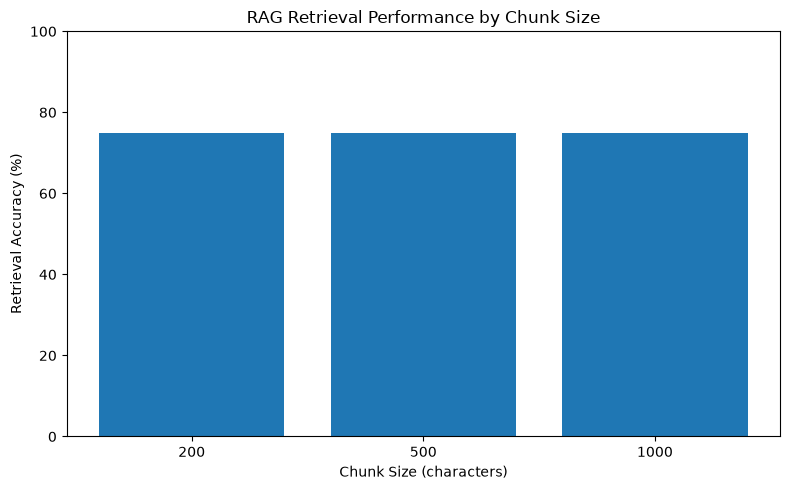

In [20]:
plt.figure(figsize=(8, 5))

plt.bar(
    accuracy_df["Chunk Size"].astype(str),
    accuracy_df["Accuracy (%)"]
)

plt.xlabel("Chunk Size (characters)")
plt.ylabel("Retrieval Accuracy (%)")
plt.title("RAG Retrieval Performance by Chunk Size")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [21]:
comparison_df.to_csv(
    "response_evaluation.csv",
    index=False
)

accuracy_df.to_csv(
    "chunk_size_comparison.csv",
    index=False
)

print("Response evaluation table saved.")
print("Chunk-size comparison saved.")

Response evaluation table saved.
Chunk-size comparison saved.


In [22]:
best_row = accuracy_df.loc[
    accuracy_df["Accuracy (%)"].idxmax()
]

best_chunk_size = int(best_row["Chunk Size"])
best_accuracy = float(best_row["Accuracy (%)"])

print("RAG RETRIEVAL PERFORMANCE REPORT")
print("-" * 40)

print("\nChunk sizes tested:", chunk_sizes)
print("Best chunk size:", best_chunk_size, "characters")
print("Retrieval accuracy:", best_accuracy, "%")

print("\nDetailed comparison:")
display(accuracy_df)

RAG RETRIEVAL PERFORMANCE REPORT
----------------------------------------

Chunk sizes tested: [200, 500, 1000]
Best chunk size: 200 characters
Retrieval accuracy: 75.0 %

Detailed comparison:


,Chunk Size,Correct_Answers,Total_Questions,Accuracy,Accuracy (%)
0,200,6,8,0.75,75.0
1,500,6,8,0.75,75.0
2,1000,6,8,0.75,75.0


In [23]:
report = f"""# Day 16 – RAG Retrieval Performance Analysis

## Objective
Build a basic RAG pipeline using company documentation,
embeddings, semantic search, and vector databases.

## Technologies
Python, Sentence Transformers, ChromaDB, FAISS,
Pandas, NumPy, Matplotlib, Jupyter Notebook.

## Experiment
Chunk sizes tested: 200, 500, and 1000 characters.
Evaluation questions: {len(evaluation_questions)}
Retrieval metric: expected information found in top 3 chunks.

## Results

{accuracy_df.to_string(index=False)}

## Best Performing Chunk Size
The best-performing tested chunk size was {best_chunk_size}
characters, with retrieval accuracy of {best_accuracy:.2f}%.

## Findings
Chunk size affects how much context is retrieved.
Smaller chunks may provide focused information, while
larger chunks may preserve surrounding context.
The measured results determine which setting performed
best on this dataset and evaluation questions.

## Limitations
The current metric checks exact expected-text matches.
It does not fully measure semantic correctness or the
quality of generated answers. The current answer baseline
is extractive rather than a generative LLM.

## Conclusion
This experiment establishes a baseline for comparing
RAG retrieval performance across different chunk sizes.
"""

with open("Comparison_Report.md", "w", encoding="utf-8") as f:
    f.write(report)

print("Comparison report generated successfully!")

Comparison report generated successfully!


In [24]:
import os

required_files = [
    "RAG_Pipeline.ipynb",
    "company_documentation.txt",
    "response_evaluation.csv",
    "chunk_size_comparison.csv",
    "Comparison_Report.md",
    "README.md",
    "requirements.txt"
]

for filename in required_files:
    status = "FOUND" if os.path.exists(filename) else "MISSING"
    print(f"{filename}: {status}")

RAG_Pipeline.ipynb: FOUND
company_documentation.txt: FOUND
response_evaluation.csv: FOUND
chunk_size_comparison.csv: FOUND
Comparison_Report.md: FOUND
README.md: MISSING
requirements.txt: MISSING
